Odnajdujemy projekt i umożliwiamy import wspólnych modułów bez wczytywania WikiArt.

In [1]:
from pathlib import Path
import sys

project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "src/restore_pipeline/super_resolution").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Uruchom notebook wewnątrz katalogu projektu.")

source_path = str(project_root / "src")

if source_path not in sys.path:
    sys.path.insert(0, source_path)


Importujemy model, predykcję i wizualizację zdjęcia użytkownika.

In [2]:
import torch
from PIL import Image
from restore_pipeline.super_resolution.checkpoints import load_model
from restore_pipeline.super_resolution.inference import predict_image
from restore_pipeline.super_resolution.visualization import (
    set_plot_style,
    plot_user_prediction,
)

from restore_pipeline.super_resolution.paths import display_path


Wskazujemy katalog modelu i zdjęcie, a skalę oraz kontekst fragmentów odczytamy z modelu.

In [3]:
EXPERIMENTS_PATH = project_root / "notebooks/igoh/models_weights/experiments"
RUN_PATH = EXPERIMENTS_PATH / 'EDSR4_x2_mse_20261109_192402_212926'
IMAGE_PATH = project_root / "notebooks/igoh/testowa_fota_2.jpg"
TILE_SIZE = 256
SHOW_PROGRESS = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


Wczytujemy best.pt i powiększamy zdjęcie w całości lub fragmentami, zachowując proporcje.

In [4]:
if RUN_PATH is None:
    raise ValueError("Wskaż RUN_PATH, np. EXPERIMENTS_PATH / nazwę katalogu modelu.")

model, checkpoint = load_model(RUN_PATH / "best.pt", DEVICE)

with Image.open(IMAGE_PATH) as image:
    input_image = image.convert("RGB")

result = predict_image(
    model, input_image, DEVICE, tile_size=TILE_SIZE, show_progress=SHOW_PROGRESS
)
print(f"Model: {checkpoint['architecture']}; epoka: {checkpoint['epoch']}")


Powiększanie fragmentami:   0%|          | 0/6 [00:00<?, ?fragment/s]

Model: {'name': 'edsr_small_v1', 'params': {'hidden_channels': 16, 'num_blocks': 4, 'scale_factor': 2}}; epoka: 50


Zapisujemy wynik PNG i porównanie z bicubic bez metryk wymagających prawdziwego HR.

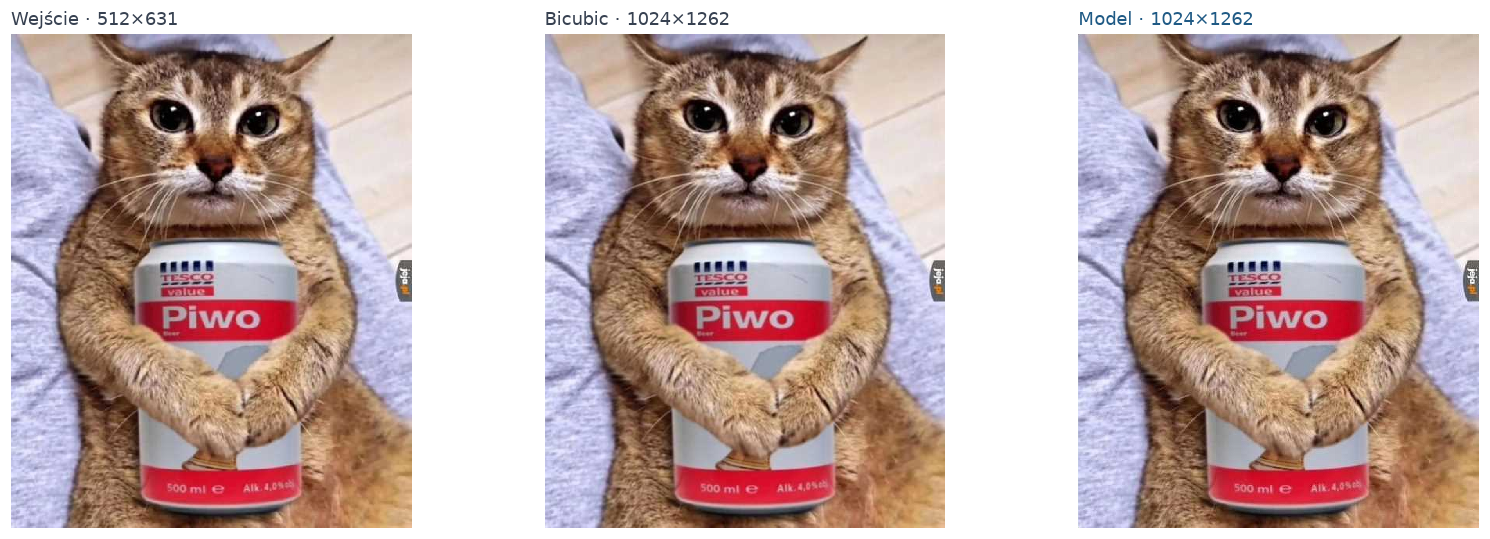

Zapisano: notebooks/igoh/models_weights/experiments/EDSR4_x2_mse_20261109_192402_212926/predictions/testowa_fota_2_x2_sr.png


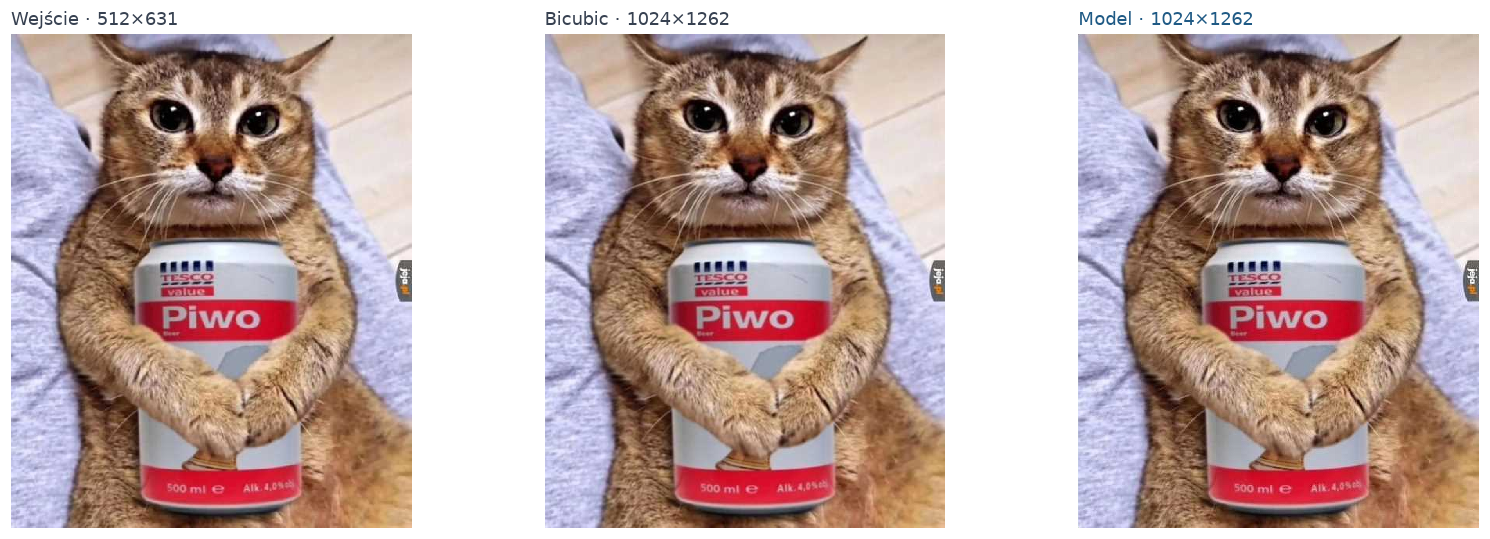

In [5]:
output_path = RUN_PATH / "predictions"
output_path.mkdir(exist_ok=True)
stem = f"{IMAGE_PATH.stem}_x{model.scale_factor}"
result_path = output_path / f"{stem}_sr.png"
result.save(result_path)

set_plot_style()
figure = plot_user_prediction(input_image, result)
figure.savefig(output_path / f"{stem}_comparison.png", dpi=150, bbox_inches="tight")
display(figure)
print(f"Zapisano: {display_path(result_path)}")
